The standardized master peptide library is the sole peptide annotation/reference file used downstream. Original annotations are retained in that file, while standardized ICTV 2025 taxonomy and protein annotations are used for analysis and plotting.

In [42]:

# 0. IMPORTS AND CONFIGURATION


import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx

from collections import defaultdict
from itertools import combinations
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import pdist
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D

sns.set_context('notebook')
sns.set_style('white')

# Input files -

Z_SL_FILE = 'z_score_df_after_FC_AG__SL_over_US_102226.csv'
Z_HBDB_FILE = 'z_hbdb_loo_results_after_FC_AG_102226.csv'
RPK_SL_FILE = '../preprocessing/earliest_tp_rpk_avg_value_for_cohort_techreps_071626.csv'
RPK_HBDB_FILE = '../preprocessing/hbdb_pass_100k_techreps_averaged_071626.csv'
LASV_ELISA_FILE = '../LASV_ELISA_Neut_and_PhIP_Seq_result_corrected_w_month_year_filtered_first_tp.csv'
REFERENCE_PEPTIDE_FILE = '../lassa_library_sequences_species_standardized_070726_ICTV_corrected.csv'


# Analysis thresholds -

Z_THRESH = 3
SENS_MIN = 0.05
SPEC_MIN = 1

# Remove taxa/accessions excluded from the original downstream analysis
TAXA_TO_REMOVE = ['Konkoviridae']
ACCESSIONS_TO_REMOVE = ['WAK75154.1', 'ANT96597.1'] #accessions mapping to ampicillin resistance proteins found in vaccine constructs



## 1. Load standardized peptide reference and z-score matrices

Only the standardized master peptide library is used to supply peptide sequence, accession, ICTV species/genus/family, and standardized protein information. The z-score files provide the participant-level seroreactivity measurements.

In [43]:

# 1. LOAD INPUTS -

# Participant z-scores
df_sl_z = pd.read_csv(Z_SL_FILE).set_index('peptide')
df_hbdb_z = pd.read_csv(Z_HBDB_FILE).set_index('peptide')

# participant rpk values
df_sl_rpk = pd.read_csv(RPK_SL_FILE).set_index('peptide')
df_hbdb_rpk = pd.read_csv(RPK_HBDB_FILE).set_index('peptide')

### identify U.S. healthies with Malaria reactivity

In [44]:
df_hbdb_z_plasmodium = df_hbdb_z.filter(regex='Plasmodium', axis=0)
df_hbdb_z_plasmodium_pass = df_hbdb_z_plasmodium > 3
df_hbdb_z_plasmodium_pass.sum(axis=1)

peptide
PF3D7_0220000.1-p1|transcript=PF3D7_0220000.1|organism=Plasmodium_falciparum_3D7|gene_product=liver_stage_antigen_3|tile_1                                     2
PF3D7_0501400.1-p1|transcript=PF3D7_0501400.1|organism=Plasmodium_falciparum_3D7|gene_product=interspersed_repeat_antigen|tile_1                               2
PF3D7_0801000.1-p1|transcript=PF3D7_0801000.1|organism=Plasmodium_falciparum_3D7|gene_product=Plasmodium_exported_protein_(PHISTc)-_unknown_function|tile_1    1
dtype: int64

In [45]:
sub = df_hbdb_z_plasmodium[df_hbdb_z_plasmodium_pass]

sub.columns[sub.notna().any()].to_list()

['HBDB-001', 'HBDB-021', 'HBDB-041', 'HBDB-059', 'HBDB-084']

In [46]:
n_reactive = df_hbdb_z_plasmodium_pass.sum(axis=0)

n_peptides = df_hbdb_z_plasmodium_pass.shape[0]

print('≥1 reactive p.falciparum peptide', (n_reactive >= 1).sum())
print('≥2 reactive p.falciparum peptide', (n_reactive >= 2).sum())
print('≥3 reactive p.falciparum peptide', (n_reactive >= 3).sum())

≥1 reactive p.falciparum peptide 5
≥2 reactive p.falciparum peptide 0
≥3 reactive p.falciparum peptide 0


## identify SL with Malaria reactivity

In [47]:
df_sl_z_plasmodium = df_sl_z.filter(regex='Plasmodium', axis=0)
df_sl_z_plasmodium_pass = df_sl_z_plasmodium > 3
df_sl_z_plasmodium_pass.sum(axis=1)

peptide
PF3D7_0220000.1-p1|transcript=PF3D7_0220000.1|organism=Plasmodium_falciparum_3D7|gene_product=liver_stage_antigen_3|tile_1                                     330
PF3D7_0501400.1-p1|transcript=PF3D7_0501400.1|organism=Plasmodium_falciparum_3D7|gene_product=interspersed_repeat_antigen|tile_1                               388
PF3D7_0801000.1-p1|transcript=PF3D7_0801000.1|organism=Plasmodium_falciparum_3D7|gene_product=Plasmodium_exported_protein_(PHISTc)-_unknown_function|tile_1    346
dtype: int64

In [48]:
n_reactive = df_sl_z_plasmodium_pass.sum(axis=0)

n_peptides = df_sl_z_plasmodium_pass.shape[0]

print('≥1 reactive p.falciparum peptide', (n_reactive >= 1).sum())
print('≥2 reactive p.falciparum peptide', (n_reactive >= 2).sum())
print('≥3 reactive p.falciparum peptide', (n_reactive >= 3).sum())

≥1 reactive p.falciparum peptide 395
≥2 reactive p.falciparum peptide 377
≥3 reactive p.falciparum peptide 292


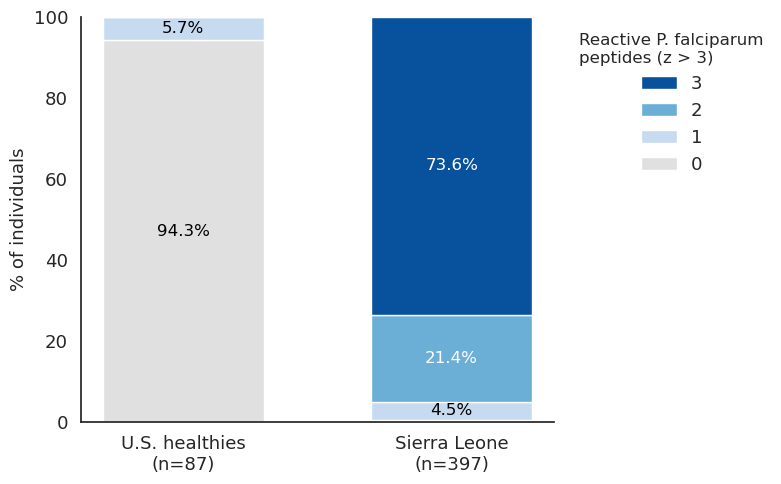

In [49]:
counts = pd.DataFrame({
    'U.S. healthies': df_hbdb_z_plasmodium_pass.sum(axis=0).value_counts(), "Sierra Leone": df_sl_z_plasmodium_pass.sum(axis=0).value_counts(), 
}).reindex(range(4), fill_value=0).fillna(0) #reindex(range(4)) forces the rows to be exactly 0, 1, 2 and 3. fills any missing category with 0.

pct = 100*counts / counts.sum()


colors = ["#e0e0e0", "#c6dbef", "#6baed6", "#08519c"]  # 0 = grey, then light → dark blue
labels = ["0", "1", "2", "3"]
width = 0.6

fig, ax = plt.subplots(figsize=(8, 5))

bottom = pd.Series(0, index=pct.columns)

for k, c, lab in zip(pct.index, colors, labels):
    ax.bar(pct.columns, pct.loc[k], bottom=bottom, color=c, label=lab,
           width=width, edgecolor="white", linewidth=1)

    for i, col in enumerate(pct.columns):
        v = pct.loc[k, col]
        if v == 0 or v <= 1:
            continue
        ax.text(i, bottom[col] + v / 2, f"{v:.1f}%", ha="center", va="center",
                fontsize=12, color="white" if k >= 2 else "black")

    bottom += pct.loc[k]


# n under each cohort label
ax.set_xticks(range(len(pct.columns)))
ax.set_xticklabels([f"{col}\n(n={int(counts[col].sum())})" for col in pct.columns], fontsize=13)

ax.set_ylabel("% of individuals", fontsize=13)
ax.set_ylim(0, 100)

ax.tick_params(axis="y", labelsize=13)

ax.legend(title="Reactive P. falciparum\npeptides (z > 3)", bbox_to_anchor=(1.02, 1),
          loc="upper left", frameon=False, reverse=True, fontsize=13)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
#plt.savefig('pfalciparum_peps_hbdb_vs_sl.svg', format='svg')
plt.show()

### 2. Define the filtered high-specificity peptide set

A peptide is considered reactive when its participant-level z-score is >3. Peptides retained for the downstream viral analysis have ≥5% sensitivity in the SL cohort and ≥100% specificity in HBDB, followed by the same exclusion of non-target taxa/artificial-vector accessions used previously.

In [50]:

# 2. PEPTIDE-LEVEL FILTERING -


pass_sl = df_sl_z > Z_THRESH
pass_hbdb = df_hbdb_z > Z_THRESH

peptide_stats = pd.DataFrame({
    'sensitivity': pass_sl.mean(axis=1),
    'specificity': 1 - pass_hbdb.mean(axis=1)
})


hits = peptide_stats[
    (peptide_stats['sensitivity'] >= SENS_MIN) &
    (peptide_stats['specificity'] >= SPEC_MIN)
].copy()

hits = pd.DataFrame(hits).reset_index('peptide')

print(hits.peptide.nunique(), 'before exclusion of taxa and accessions')


1292 before exclusion of taxa and accessions


In [51]:
peps_metadata = pd.read_csv(REFERENCE_PEPTIDE_FILE)
peps_metadata.rename(columns={'seq_id':'peptide'}, inplace=True)

In [52]:
hits = hits.merge(peps_metadata, on='peptide', how='left')

In [53]:
hits.to_csv('pep_hits__after_FC_AG_z_score_102226.csv')

In [54]:

# Original analysis exclusions
hits = hits[
    ~hits['family'].isin(TAXA_TO_REMOVE)
].copy()

hits = hits[
    ~hits['accession'].isin(ACCESSIONS_TO_REMOVE)
].copy()


print(f'Filtered peptide hits: {hits.peptide.nunique()}')
print(f'Unique standardized species: {hits.species.nunique()}')
print(f'Unique standardized genera: {hits.genus.nunique()}')
print(f'Unique standardized families: {hits.family.nunique()}')

Filtered peptide hits: 1287
Unique standardized species: 367
Unique standardized genera: 43
Unique standardized families: 10


In [55]:
hits.to_csv('pep_hits_wo_taxa_to_remove_091826.csv')

In [56]:
print(hits.shape)

(1287, 21)


In [57]:
hits['family'].unique()

array(['Hantaviridae', 'Phenuiviridae', 'Arenaviridae', 'Filoviridae',
       'Flaviviridae', 'Togaviridae', 'Paramyxoviridae', 'Nairoviridae',
       'Matonaviridae', 'Trypanosomatidae'], dtype=object)

## convert data to long format and add z score and RPK score to the peptide hits

In [58]:

# 3. LONG-FORM PARTICIPANT DATA -

df_z = pd.concat([df_sl_z, df_hbdb_z], axis=1)
df_rpk = pd.concat([df_sl_rpk, df_hbdb_rpk], axis=1)

z_long = (
    df_z.loc[hits['peptide']]
    .reset_index()
    .melt(
        id_vars='peptide',
        var_name='individual',
        value_name='z_score'
    )
)

rpk_long = (
    df_rpk.loc[hits['peptide']]
    .reset_index()
    .melt(
        id_vars='peptide', 
        var_name='individual', 
        value_name='rpk'
    )
)

long = z_long.merge(
    rpk_long, 
    on=['peptide', 'individual'], 
    how='left'
)


long = long.merge(
    hits[
        [
            'peptide', 'sequence', 'species', 'genus', 'family',
            'protein_std', 'accession'
        ]
    ].drop_duplicates('peptide'),
    on='peptide',
    how='left'
)

long['cohort'] = np.where(
    z_long['individual'].str.startswith('HBDB-'),
    'HBDB',
    'SL'
)

long['category'] = np.select(
    [
        long['individual'].str.startswith('S-'),
        long['individual'].str.startswith('C-'),
        long['individual'].str.startswith('HBDB-')
    ],
    [
        'Lassa survivor',
        'Household contact',
        'US healthy'
    ],
    default='Unknown'
)

long['reactive'] = long['z_score'] > Z_THRESH


print(long['category'].nunique())

3


In [59]:
long.to_csv('long_w_fc_before_z_score_102226.csv', index=False)

### what is the intersection between pep hits with this FC AG method followed by z scoring part and direct RPK z scoring method? 

In [60]:
pep_hits_fc = hits

hits_old = pd.read_csv('../pep_hits_091826.csv')

In [61]:
a = set(pep_hits_fc['peptide'].str.strip())
b = set(hits_old['peptide'].str.strip())

In [62]:
print(f"shared {len(a & b)}") 
print(f"only in fc:{len(a -b)}")
print(f"only in old: {len(b-a)}")

shared 1287
only in fc:0
only in old: 5


In [63]:
only_old = sorted(b - a)
hits_old[hits_old['peptide'].isin(only_old)].describe()

,Unnamed: 0,sensitivity,specificity,fragment,AG_median
count,5.000000,5.000000,5.0,5.000000,5.000000
mean,469.800000,0.102267,1.0,40.200000,0.024766
std,177.805231,0.052160,0.0,27.151427,0.055378
min,160.000000,0.062972,1.0,7.000000,0.000000
25%,523.000000,0.083123,1.0,16.000000,0.000000
50%,524.000000,0.083123,1.0,50.000000,0.000000
75%,525.000000,0.088161,1.0,60.000000,0.000000
max,617.000000,0.193955,1.0,68.000000,0.123830


In [64]:
long.sort_values(by='z_score', ascending=False).groupby('peptide').first().head(5)

,individual,z_score,rpk,sequence,species,genus,family,protein_std,accession,cohort,category,reactive
peptide,,,,,,,,,,,,
AAA16239.1|polypeptide|Orthohantavirus_thailandense|isolate=?|?|?|?|segment=?|strain=Thai749|tile_41,S-186_SA1_G3,18.162058,414.802889,SFQSFNTSSIHFTDERLMEDPDGMLRDHINIVVTKDIDFENLAENL,Orthohantavirus thailandense,Orthohantavirus,Hantaviridae,glycoprotein,AAA16239.1,SL,Lassa survivor,True
AAA47458.1|?|sandfly_fever_Sicilian_virus|isolate=?|?|?|?|segment=?|strain=?|tile_9,C-454-2_3_F4,13.401327,705.439539,LRGAQKRDIEESFSQPMLAAINSSFIDNTQRRAFLTKFGILTSGAR,Phlebovirus siciliaense,Phlebovirus,Phenuiviridae,nucleoprotein,AAA47458.1,SL,Household contact,True
AAB58486.1|precursor|Pichinde_virus|temperature_sensitive_mutant_ts908|?|?|?|?|?|tile_17,C-146-2_1_F7,22.123635,86.583604,LKQLAKIPYCNYTKFWYINDTITGRHSLPQCWLVHNGSYLNETHFK,Mammarenavirus caliense,Mammarenavirus,Arenaviridae,glycoprotein,AAB58486.1,SL,Household contact,True
AAK17901.1|protein|Mammarenavirus_piritalense|?|?|?|?|S|prototype_strain_VAV-488|tile_16,S-506_SA3_H9,9.343970,162.250784,RNGGSPRLSQLSHAKEEQILEGLKRLDSKATTWIDIEGTPNDPVEL,Mammarenavirus piritalense,Mammarenavirus,Arenaviridae,nucleoprotein,AAK17901.1,SL,Lassa survivor,True
AAK17901.1|protein|Mammarenavirus_piritalense|?|?|?|?|S|prototype_strain_VAV-488|tile_5,C-502-2_6_D9,11.137107,192.477344,LSKDELMELASDLQKLKKKVLRVEGSGQPGVYAGNLTTTQLEQRSK,Mammarenavirus piritalense,Mammarenavirus,Arenaviridae,nucleoprotein,AAK17901.1,SL,Household contact,True


In [65]:
pep_hits_fc.sort_values(by='sensitivity', ascending=False).head(5)

,peptide,sensitivity,specificity,sequence,accession,protein_name,gene,segment,order,family,...,genus,species,isolate,taxonomy_lineage,collection_date,geo_loc_name,host,protein_std,fragment,collection_date_standardized
866,XQZ82370.1|polymerase|Bandavirus_dabieense|iso...,0.760705,1.0,MRSKLTEMVEKNVVPLTTQELVDILEEDIDFSDVIAVELSEGSLDI,XQZ82370.1,RNA polymerase,NaN,L,Hareavirales,Phenuiviridae,...,Bandavirus,Bandavirus dabieense,WQS,Viruses;Riboviria;Orthornavirae;Negarnaviricot...,2/20/25,China: Quzhou,Homo sapiens,polymerase,85,2/20/25
1019,YP_009666941.1|polymerase|Guertu_virus|isolate...,0.707809,1.0,MRSKLSELVEKNVIPLTTQELVDILEEDIDFSDVIATELSEGSLDI,YP_009666941.1,RNA-dependent RNA polymerase,FLB06_sLgp1,L,Hareavirales,Phenuiviridae,...,Bandavirus,Bandavirus guertuense,NaN,Viruses;Riboviria;Orthornavirae;Negarnaviricot...,13-May,China,Dermacentor nuttalli,polymerase,85,2013-05
14,ABI96821.1|protein|Mammarenavirus_choriomening...,0.513854,1.0,SRCIEMDGADKSGCIHNHDDKSVETILIESGIVCPGLPLIIPDGYK,ABI96821.1,L protein,L,L,Hareavirales,Arenaviridae,...,Mammarenavirus,Mammarenavirus choriomeningitidis,NaN,Viruses;Riboviria;Orthornavirae;Negarnaviricot...,NaN,NaN,NaN,polymerase,3,NaN
654,WRI50013.1|polymerase|Norwavirus_sp.|isolate=?...,0.501259,1.0,KAKDARKSRALDFEEDRDQRTIPLRTMETAMLFDTEEDEGSIPESV,WRI50013.1,RNA-dependent RNA polymerase,NaN,NaN,Hareavirales,Nairoviridae,...,Norwavirus,Norwavirus sp.,NaN,Viruses;Riboviria;Orthornavirae;Negarnaviricot...,NaN,Bulgaria,Ixodes ricinus,polymerase,19,NaN
605,WLD55688.1|polyprotein|dengue_virus_type_2|iso...,0.478589,1.0,SWMEDKTPVTTWEDVPYLGKREDQWCGSLIGLTSRATWAQNILTAI,WLD55688.1,polyprotein,POLY,NaN,Amarillovirales,Flaviviridae,...,Orthoflavivirus,Orthoflavivirus denguei,S593,Viruses;Riboviria;Orthornavirae;Kitrinoviricot...,9/30/19,Sri Lanka,Homo sapiens,polymerase,145,9/30/19


In [66]:
df_ag = pd.read_csv('df_AG.csv')

In [67]:
df_ag = df_ag.set_index('peptide')

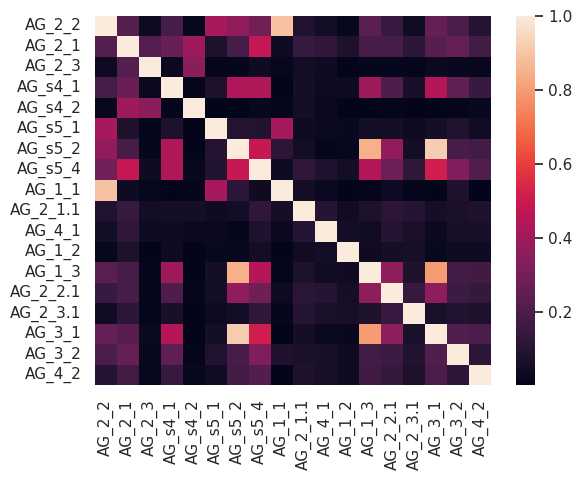

In [68]:
matrix = df_ag.corr(method='pearson')
sns.heatmap(matrix)
plt.show()

In [69]:
df_ag_avg = df_ag.mean(axis=1)

In [70]:
only_old = sorted(b - a)
df_ag_avg[df_ag_avg.index.isin(only_old)].describe()
df_ag_avg.describe()

count    90132.000000
mean         2.109484
std         10.832620
min          1.000000
25%          1.049102
50%          1.384128
75%          2.188017
max       2577.838960
dtype: float64

In [71]:
lost_lowbg = df_ag_avg[df_ag_avg.index.isin(only_old) & (df_ag_avg < 1.5)]
print(len(lost_lowbg))

3


In [72]:
hits_old['ag'] = df_ag_avg.reindex(hits_old['peptide']).values
hits_old['ag'].describe()

count    1292.000000
mean        3.247503
std         3.233811
min         1.000000
25%         1.703457
50%         2.503100
75%         3.761489
max        78.511342
Name: ag, dtype: float64

In [73]:
df_ag_avg.describe()

count    90132.000000
mean         2.109484
std         10.832620
min          1.000000
25%          1.049102
50%          1.384128
75%          2.188017
max       2577.838960
dtype: float64

In [74]:
n_high = (df_ag_avg > 78.5).sum()
print(n_high, "peptides above your hits' max")
print("expected in a random 1292:", 1292 * n_high / len(df_ag_avg))

24 peptides above your hits' max
expected in a random 1292: 0.34402875782186126


In [75]:
df_ag_avg.nlargest(24)

peptide
BAU51655.1|polymerase|Tofla_virus|isolate=?|Haemaphysalis_formsensis|Japan|2014-05-09|segment=L|strain=Nag-Hfor-2014|tile_150                                  2577.838960
AHE13863.1|L|Sclerotinia_sclerotiorum_phlebo-like_virus_1|isolate=Bz8|Sclerotinia_sclerotiorum|Brazil|01-Aug-2008|segment=?|strain=?|tile_40                   1442.167501
PF3D7_0501400.1-p1|transcript=PF3D7_0501400.1|organism=Plasmodium_falciparum_3D7|gene_product=interspersed_repeat_antigen|tile_1                                797.246767
NP_002046.1||tile_9                                                                                                                                             470.190380
PF3D7_0801000.1-p1|transcript=PF3D7_0801000.1|organism=Plasmodium_falciparum_3D7|gene_product=Plasmodium_exported_protein_(PHISTc)-_unknown_function|tile_1     322.396886
AMZ00406.1|L|Mammarenavirus_machupoense|9430069|Homo_sapiens|Bolivia|01-Jan-1994|L|?|tile_91                                             

In [76]:
hits_old['peptide'].isin(df_ag_avg.nlargest(24).index).sum()

np.int64(1)